In [1]:
%pip install numpy pandas scikit-learn xgboost ucimlrepo matplotlib seaborn joblib ipykernel jupyter


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [ ]:
# Run once if dependencies are missing:
# %pip install numpy pandas scikit-learn ucimlrepo matplotlib joblib

import sys
import time
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    average_precision_score, precision_recall_curve,
    ConfusionMatrixDisplay, classification_report,
)

ROOT = Path.cwd()
if not (ROOT / 'src' / 'data.py').exists():
    ROOT = ROOT.parent
if not (ROOT / 'src' / 'data.py').exists():
    raise FileNotFoundError('Run this notebook from repository root or project-notebooks/')
sys.path.insert(0, str(ROOT))

from src.data import load_dataset, split, feature_types
from src.corrupt import inject_missing_mcar, inject_missing_mnar, flip_labels, perturb_features

split_seed = 42
validation_split = 0.25
experiment_seeds = [42, 43, 44]
dataset_names = ['adult', 'ai4i']
model_name = 'random forest'

results_dir = ROOT / 'results' / 'random_forest'
models_dir = ROOT / 'models' / 'random_forest'
results_dir.mkdir(parents=True, exist_ok=True)
models_dir.mkdir(parents=True, exist_ok=True)
print('Project root:', ROOT)

Project root: /Users/zhanghaoran/Documents/zyw/UC_davis/Subjects/ECS171/ECS-171-Project


In [ ]:
clean_data = {}
split_sizes = []

for name in dataset_names:
    X, y = load_dataset(name)
    X_train_full, X_test, y_train_full, y_test = split(X, y, seed=split_seed)
    X_train, X_val, y_train, y_val = train_test_split(
        X_train_full, y_train_full, test_size=validation_split,
        stratify=y_train_full, random_state=split_seed
    )
    clean_data[name] = dict(X_train=X_train, X_val=X_val, X_test=X_test,
                            y_train=y_train, y_val=y_val, y_test=y_test)
    split_sizes.append(dict(dataset=name, train=len(X_train), validation=len(X_val),
                            test=len(X_test), positive_rate=float(y.mean())))

split_df = pd.DataFrame(split_sizes)
display(split_df)

,dataset,train,validation,test,positive_rate
0,adult,24863,8288,8288,0.239388
1,ai4i,6000,2000,2000,0.033900


In [ ]:
def make_rf_preprocessor(X_train):
    numeric_cols, categorical_cols = feature_types(X_train)
    return ColumnTransformer([
        # add_indicator / a 'Missing' category keep the information that a value was missing (EDA)
        ('numeric', SimpleImputer(strategy='median', add_indicator=True), numeric_cols),
        ('categorical', Pipeline([
            ('impute', SimpleImputer(strategy='constant', fill_value='Missing')),
            ('onehot', OneHotEncoder(handle_unknown='ignore'))
        ]), categorical_cols)
    ])


def make_rf_pipeline(X_train, seed=42, **rf_params):
    params = {'n_estimators': 200, 'random_state': seed, 'n_jobs': -1}
    params.update(rf_params)
    return Pipeline([
        ('preprocess', make_rf_preprocessor(X_train)),
        ('model', RandomForestClassifier(**params))
    ])

pipelines = {name: make_rf_pipeline(clean_data[name]['X_train'])
             for name in dataset_names}

Random Forest pipelines ready


In [ ]:
param_distributions = {
    'model__n_estimators': [150, 300, 500],
    'model__max_depth': [None, 8, 16, 24],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 4],
    'model__max_features': ['sqrt', 0.5],
    'model__class_weight': [None, 'balanced', 'balanced_subsample'],
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=split_seed)
searches, best_params, search_results = {}, {}, []

for name in dataset_names:
    print(f'\nTuning Random Forest on {name}')
    search = RandomizedSearchCV(
        estimator=pipelines[name], param_distributions=param_distributions,
        n_iter=12, scoring='average_precision', cv=cv,
        random_state=split_seed, n_jobs=1, refit=False, verbose=1
    )
    search.fit(clean_data[name]['X_train'], clean_data[name]['y_train'])
    searches[name] = search
    best_params[name] = {k.replace('model__', ''): v for k, v in search.best_params_.items()}
    search_results.append(dict(dataset=name, best_cv_average_precision=search.best_score_,
                               best_params=str(best_params[name])))

best_params_df = pd.DataFrame(search_results)
display(best_params_df)
best_params_df.to_csv(results_dir / 'hyperparameter_search.csv', index=False)


Tuning Random Forest on adult
Fitting 5 folds for each of 12 candidates, totalling 60 fits

Tuning Random Forest on ai4i
Fitting 5 folds for each of 12 candidates, totalling 60 fits


,dataset,best_cv_average_precision,best_params
0,adult,0.822453,"{'n_estimators': 500, 'min_samples_split': 10,..."
1,ai4i,0.761760,"{'n_estimators': 500, 'min_samples_split': 5, ..."


In [ ]:
def best_f1_threshold(y_true, prob):
    precision, recall, thresholds = precision_recall_curve(y_true, prob)
    if len(thresholds) == 0:
        return 0.5
    f1_values = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-12)
    return float(thresholds[np.argmax(f1_values)])


def metric_row(y_true, prob, threshold):
    pred = (prob >= threshold).astype(int)
    return dict(
        accuracy=accuracy_score(y_true, pred),
        precision=precision_score(y_true, pred, zero_division=0),
        recall=recall_score(y_true, pred, zero_division=0),
        f1=f1_score(y_true, pred, zero_division=0),
        average_precision=average_precision_score(y_true, prob),
    )

normal_models, normal_thresholds, training_times = {}, {}, {}
normal_val_metrics = []

for name in dataset_names:
    d = clean_data[name]
    for seed in experiment_seeds:
        model = make_rf_pipeline(d['X_train'], seed=seed, **best_params[name])
        start = time.perf_counter()
        model.fit(d['X_train'], d['y_train'])
        elapsed = time.perf_counter() - start
        normal_models[(name, seed)] = model
        training_times[(name, seed)] = elapsed
        val_prob = model.predict_proba(d['X_val'])[:, 1]
        train_prob = model.predict_proba(d['X_train'])[:, 1]
        threshold = best_f1_threshold(d['y_val'], val_prob)
        normal_thresholds[(name, seed)] = threshold
        normal_val_metrics.append(dict(
            dataset=name, seed=seed, threshold=threshold,
            **metric_row(d['y_val'], val_prob, threshold),
            train_average_precision=average_precision_score(d['y_train'], train_prob),
            training_seconds=elapsed,
        ))
        print(f'{name} seed={seed}: time={elapsed:.1f}s, threshold={threshold:.3f}')

normal_val_df = pd.DataFrame(normal_val_metrics)
display(normal_val_df.round(4))

adult seed=42: time=10.5s, threshold=0.560
adult seed=43: time=12.1s, threshold=0.610
adult seed=44: time=10.7s, threshold=0.590
ai4i seed=42: time=1.3s, threshold=0.443
ai4i seed=43: time=1.2s, threshold=0.517
ai4i seed=44: time=1.2s, threshold=0.506


,dataset,seed,threshold,accuracy,precision,recall,f1,average_precision,train_average_precision,training_seconds
0,adult,42,0.5602,0.8551,0.6646,0.7969,0.7247,0.8265,0.8820,10.4694
1,adult,43,0.6096,0.8615,0.6912,0.7616,0.7247,0.8259,0.8818,12.1285
2,adult,44,0.5902,0.8591,0.6804,0.7757,0.7249,0.8262,0.8821,10.6868
3,ai4i,42,0.4434,0.9800,0.7188,0.6765,0.6970,0.7235,0.9978,1.2636
4,ai4i,43,0.5166,0.9800,0.7593,0.6029,0.6721,0.7217,0.9977,1.2355
5,ai4i,44,0.5058,0.9810,0.7679,0.6324,0.6935,0.7193,0.9979,1.2477


,dataset,seed,threshold,accuracy,precision,recall,f1,average_precision
0,adult,42,0.5602,0.8534,0.6597,0.8004,0.7233,0.8318
1,adult,43,0.6096,0.8616,0.6876,0.7732,0.7279,0.8320
2,adult,44,0.5902,0.8575,0.6748,0.7812,0.7241,0.8326
3,ai4i,42,0.4434,0.9810,0.7083,0.7500,0.7286,0.7899
4,ai4i,43,0.5166,0.9825,0.7895,0.6618,0.7200,0.7937
5,ai4i,44,0.5058,0.9815,0.7719,0.6471,0.7040,0.7859



ADULT classification report (seed 42)
              precision    recall  f1-score   support

           0       0.93      0.87      0.90      6304
           1       0.66      0.80      0.72      1984

    accuracy                           0.85      8288
   macro avg       0.80      0.84      0.81      8288
weighted avg       0.87      0.85      0.86      8288



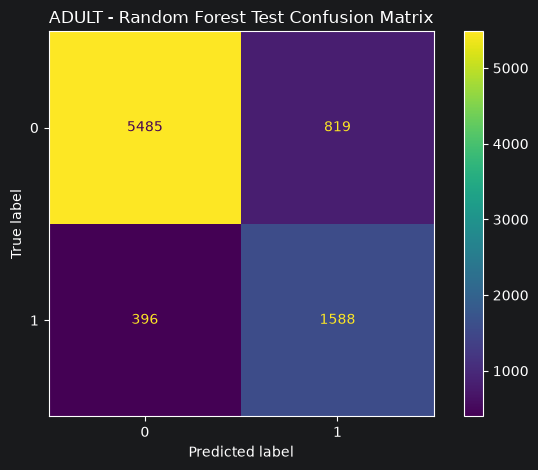


AI4I classification report (seed 42)
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1932
           1       0.71      0.75      0.73        68

    accuracy                           0.98      2000
   macro avg       0.85      0.87      0.86      2000
weighted avg       0.98      0.98      0.98      2000



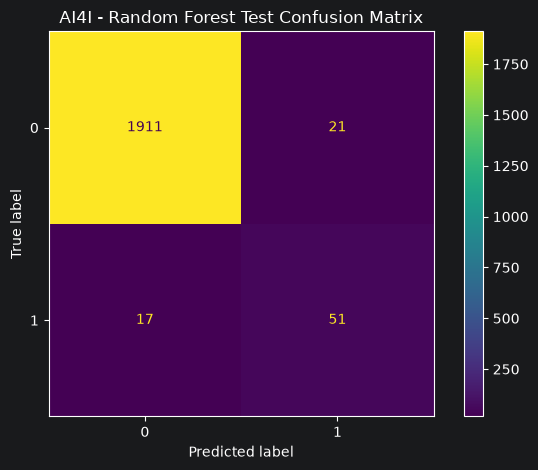

In [ ]:
normal_test_metrics = []
for name in dataset_names:
    d = clean_data[name]
    for seed in experiment_seeds:
        model = normal_models[(name, seed)]
        prob = model.predict_proba(d['X_test'])[:, 1]
        threshold = normal_thresholds[(name, seed)]
        normal_test_metrics.append(dict(dataset=name, seed=seed, threshold=threshold,
                                        **metric_row(d['y_test'], prob, threshold)))

normal_test_df = pd.DataFrame(normal_test_metrics)
display(normal_test_df.round(4))

for name in dataset_names:
    d = clean_data[name]
    model = normal_models[(name, experiment_seeds[0])]
    threshold = normal_thresholds[(name, experiment_seeds[0])]
    pred = (model.predict_proba(d['X_test'])[:, 1] >= threshold).astype(int)
    print(f'\n{name.upper()} classification report (seed 42)')
    print(classification_report(d['y_test'], pred, zero_division=0))
    ConfusionMatrixDisplay.from_predictions(d['y_test'], pred)
    plt.title(f'{name.upper()} - Random Forest Test Confusion Matrix')
    plt.tight_layout()
    plt.savefig(results_dir / f'{name}_confusion_matrix.png', dpi=150)
    plt.show()

In [ ]:
metrics = ['accuracy', 'precision', 'recall', 'f1', 'average_precision']
val_summary = normal_val_df.groupby('dataset')[metrics].mean()
test_summary = normal_test_df.groupby('dataset')[metrics].mean()
comparison_df = pd.concat({'validation': val_summary, 'test': test_summary}, axis=1)
display(comparison_df.round(4))
comparison_df.to_csv(results_dir / 'validation_test_comparison.csv')

validation                                                 test  \
          accuracy precision  recall      f1 average_precision accuracy   
dataset                                                                   
adult       0.8586    0.6787  0.7781  0.7248            0.8262   0.8575   
ai4i        0.9803    0.7486  0.6373  0.6875            0.7215   0.9817   

                                                     
        precision  recall      f1 average_precision  
dataset                                              
adult      0.6740  0.7849  0.7251            0.8321  
ai4i       0.7566  0.6863  0.7175            0.7898

In [ ]:
clean_results_dir = results_dir / 'clean'
clean_results_dir.mkdir(parents=True, exist_ok=True)
normal_val_df.to_csv(clean_results_dir / 'validation.csv', index=False)
normal_test_df.to_csv(clean_results_dir / 'test.csv', index=False)
# Also provide Logistic Regression-style filenames for consistency
normal_val_df.to_csv(results_dir / 'validation_metrics.csv', index=False)
normal_test_df.to_csv(results_dir / 'test_metrics.csv', index=False)

for name in dataset_names:
    seed = experiment_seeds[0]
    file_path = models_dir / f'{name}_clean.joblib'
    pipeline = normal_models[(name, seed)]
    joblib.dump({'preprocessor': pipeline.named_steps['preprocess'],
                 'model': pipeline.named_steps['model'],
                 'threshold': normal_thresholds[(name, seed)]}, file_path)
    print('Saved', file_path)

Saved /Users/zhanghaoran/Documents/zyw/UC_davis/Subjects/ECS171/ECS-171-Project/models/random_forest/adult_clean.joblib
Saved /Users/zhanghaoran/Documents/zyw/UC_davis/Subjects/ECS171/ECS-171-Project/models/random_forest/ai4i_clean.joblib


Corrupted Data

In [ ]:
corruption_rates = [0.1, 0.2, 0.3, 0.4]
corruption_seed = 42
noise_scale = 1.0

# Same corruption setup, rates and seeds as the XGBoost and neural network notebooks.
# This model fills in missing values first, so `mcar` here matches `mcar_imputed` in the XGBoost notebook.
# mcar_test = same as mcar, but the test set has missing values too
corruption_types = ["mcar", "mcar_test", "mnar", "noise", "label_flip"]
MNAR_COLUMNS = {"adult": ["education_num"], "ai4i": ["Tool_wear", "Torque"]}

corrupted_val_metrics, corrupted_test_metrics, missingness = [], [], []

for corruption_type in corruption_types:
    corrupted_results_dir = results_dir / corruption_type
    corrupted_results_dir.mkdir(parents=True, exist_ok=True)

    for dataset_name in dataset_names:
        for missing_rate in corruption_rates:
            print(f"Training {model_name} on {dataset_name} with {missing_rate:.0%} {corruption_type}")

            # use the same splits as the normal models
            data = clean_data[dataset_name].copy()
            train_rng = np.random.default_rng(corruption_seed)
            val_rng = np.random.default_rng(corruption_seed + 1)
            test_rng = np.random.default_rng(corruption_seed + 2)

            # corrupt the training and validation sets, the test set stays clean (except for mcar_test)
            if corruption_type in ["mcar", "mcar_test"]:
                data["X_train"] = inject_missing_mcar(data["X_train"], missing_rate, rng=train_rng)
                data["X_val"] = inject_missing_mcar(data["X_val"], missing_rate, rng=val_rng)
                if corruption_type == "mcar_test":
                    data["X_test"] = inject_missing_mcar(data["X_test"], missing_rate, rng=test_rng)
            elif corruption_type == "mnar":
                # value-dependent missingness on the most informative features (EDA): larger values go missing more often
                for column in MNAR_COLUMNS[dataset_name]:
                    data["X_train"] = inject_missing_mnar(data["X_train"], missing_rate, rng=train_rng, column=column)
                    data["X_val"] = inject_missing_mnar(data["X_val"], missing_rate, rng=val_rng, column=column)
            elif corruption_type == "noise":
                data["X_train"] = perturb_features(data["X_train"], missing_rate, rng=train_rng, noise_scale=noise_scale)
                data["X_val"] = perturb_features(data["X_val"], missing_rate, rng=val_rng, noise_scale=noise_scale)
            elif corruption_type == "label_flip":
                data["y_train"] = flip_labels(data["y_train"], missing_rate, rng=train_rng)
                data["y_val"] = flip_labels(data["y_val"], missing_rate, rng=val_rng)

            #check missingness
            missingness.append({
                "corruption_type": corruption_type,
                "dataset": dataset_name,
                "missing_rate": missing_rate,
                "corruption_seed": corruption_seed,
                "training_missing_pct": 100 * data["X_train"].isna().to_numpy().mean(),
                "validation_missing_pct": 100 * data["X_val"].isna().to_numpy().mean(),
                "test_missing_pct": 100 * data["X_test"].isna().to_numpy().mean(),
            })

            for seed in experiment_seeds:
                # same hyperparameters as the normal models; the pipeline refits
                # its preprocessing (imputation, encoding) on the corrupted training set
                model = make_rf_pipeline(data["X_train"], seed=seed, **best_params[dataset_name])
                start_time = time.perf_counter()
                model.fit(data["X_train"], data["y_train"])
                training_seconds = time.perf_counter() - start_time

                # pick the threshold with the best F1 on validation, using the clean validation labels
                # (with flipped labels, the best-F1 threshold is "predict everything positive")
                threshold = best_f1_threshold(clean_data[dataset_name]["y_val"],
                                              model.predict_proba(data["X_val"])[:, 1])

                for X_eval, y_eval, metrics_list in [(data["X_val"], data["y_val"], corrupted_val_metrics),
                                                     (data["X_test"], data["y_test"], corrupted_test_metrics)]:
                    prob = model.predict_proba(X_eval)[:, 1]
                    metrics_list.append({
                        "corruption_type": corruption_type,
                        "dataset": dataset_name,
                        "missing_rate": missing_rate,
                        "corruption_seed": corruption_seed,
                        "seed": seed,
                        "threshold": threshold,
                        **metric_row(y_eval, prob, threshold),
                        "training_seconds": training_seconds,
                        "hyperparameters": best_params[dataset_name],
                    })

        #save results after each corruption type and dataset
        corrupted_val_df = pd.DataFrame(corrupted_val_metrics)
        corrupted_test_df = pd.DataFrame(corrupted_test_metrics)
        corrupted_val_df[corrupted_val_df.corruption_type == corruption_type].to_csv(corrupted_results_dir / "validation.csv", index=False)
        corrupted_test_df[corrupted_test_df.corruption_type == corruption_type].to_csv(corrupted_results_dir / "test.csv", index=False)
        pd.DataFrame(missingness).to_csv(results_dir / "missingness.csv", index=False)

#average test performance across the three seeds
test_summary = corrupted_test_df.groupby(["corruption_type", "dataset", "missing_rate"])[
    ["accuracy", "precision", "recall", "f1", "average_precision"]
].agg(["mean", "std"])

test_summary.to_csv(results_dir / "test_summary.csv")
display(test_summary.round(4))

Skipped optional robustness experiments. Set RUN_CORRUPTION_EXPERIMENTS=True to enable.


Test performance as training data gets worse

In [ ]:
baseline_ap = normal_test_df.groupby("dataset")["average_precision"].mean()
plot_df = corrupted_test_df.groupby(["corruption_type", "dataset", "missing_rate"])["average_precision"].mean().reset_index()

labels = {"mcar": "Missing (filled in first)", "mcar_test": "Missing in test too (filled in first)",
          "noise": "Noisy measurements", "label_flip": "Flipped labels"}
colors = {"mcar": "#eb6834", "mnar": "#2a78d6", "mcar_test": "#eb6834", "noise": "#1baf7a", "label_flip": "#eda100"}
markers = {"mcar": "s", "mnar": "o", "mcar_test": "s", "noise": "^", "label_flip": "D"}
titles = {"adult": "Adult Income", "ai4i": "AI4I Predictive Maintenance"}

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, dataset_name in zip(axes, dataset_names):
    for corruption_type in corruption_types:
        rows = plot_df[(plot_df.corruption_type == corruption_type) & (plot_df.dataset == dataset_name)]
        # every line starts at the clean baseline (0% corrupted)
        x = [0] + list(100 * rows.missing_rate)
        y = [baseline_ap[dataset_name]] + list(rows.average_precision)
        ax.plot(x, y, color=colors[corruption_type], marker=markers[corruption_type],
                markersize=8, linewidth=2, label=labels[corruption_type],
                linestyle="--" if corruption_type.endswith("_test") else "-")
    ax.set_title(titles[dataset_name])
    ax.set_xlabel("Corrupted training and validation data (%)")
    ax.set_ylabel("Test average precision")
    ax.set_xticks([0, 10, 20, 30, 40])
    ax.grid(axis="y", color="#e5e5e2", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False)
plt.tight_layout()
plt.savefig(results_dir / "test_ap_vs_corruption.png", dpi=150)
plt.show()